In [12]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib
from scipy.stats import gaussian_kde

pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.options.display.float_format = '{:.6f}'.format

matplotlib.rc('xtick', labelsize=16)
matplotlib.rc('ytick', labelsize=16)

df = pd.read_csv("participants_info.csv", delimiter=",")

# Modality availability (homogeneous rule used across all figures):
# a participant counts as having a modality if ANY of their sessions has it
df_mod = pd.read_csv("modalities_info.csv", delimiter=",")[["participant_id", "anat", "fmri", "dwi"]].copy()
for _col in ["anat", "fmri", "dwi"]:
    df_mod[_col] = pd.to_numeric(df_mod[_col], errors="coerce").fillna(0)
df_mod = df_mod.groupby("participant_id", as_index=False)[["anat", "fmri", "dwi"]].max()

df = pd.merge(df, df_mod, on="participant_id", how="left")
for _col in ["anat", "fmri", "dwi"]:
    df[_col] = pd.to_numeric(df[_col], errors="coerce").fillna(0)

# Drop rows without a participant_id and keep one row per participant
df = (
    df[df["participant_id"].notna()]
    .drop_duplicates(subset="participant_id", keep="first")
    .copy()
)

# Map group codes to labels
group_map = {
    0: "HC",
    0.1: "HC Sibling",
    1: "SCHZ",
    1.1: "SCHZ Sibling",
    2: "BD",
    3: "FEP",
    4: "MDD",
    5: "CHR",
    6: "ADHD",
    7: "PTSD",
    8: "GAD",
    9: "SAD",
    10: "SUD",
    11: "OCD",
    12: "SEAD",
    13: "ASD",
    14: "CPS",
    15: "Stroke",
    16: "BPD",
    17: "ARMS",
    18: "AN",
    19: "WR",
    20: "AUD",
    21: "Panic Episode",
    22: "Agoraphobia"
}

df_unique = df.copy()

# Split entries that contain ';' and expand multiple-group participants
df_unique["group_split"] = df_unique["group"].astype(str).str.split(";")
df_exploded = df_unique.explode("group_split")
df_exploded["group_split"] = pd.to_numeric(
    df_exploded["group_split"].str.strip(), errors="coerce"
)
df_exploded["group_label"] = df_exploded["group_split"].map(group_map)

# Counts / percentages per group
counts = df_exploded["group_label"].value_counts()
n_participants = df_unique["participant_id"].nunique()

result = pd.DataFrame({
    "count": counts,
    "percentage": counts / n_participants * 100
}).sort_values("count", ascending=False)

print(result)

# -----------------------------
# HC vs PATIENT SUBSETS
# -----------------------------
hc_ids = (
    df_exploded.loc[df_exploded["group_label"] == "HC", "participant_id"]
    .dropna().unique()
)
patient_ids = (
    df_exploded.loc[
        (df_exploded["group_label"].notna()) &
        (df_exploded["group_label"] != "HC"),
        "participant_id"
    ].dropna().unique()
)

df_hc = df[df["participant_id"].isin(hc_ids)].copy()
df_patients = df[df["participant_id"].isin(patient_ids)].copy()

print(f"HC participants: {len(hc_ids)} | Patient participants: {len(patient_ids)} | Total: {n_participants}")

# -----------------------------
# MODALITY % (ANY-SESSION RULE)
# -----------------------------
modalities = ["anat", "fmri", "dwi"]
labels = ["sMRI", "fMRI", "DWI"]

modality_summary = pd.DataFrame({
    "all_%": [df[m].mean() * 100 for m in modalities],
    "patients_%": [df_patients[m].mean() * 100 for m in modalities],
    "HC_%": [df_hc[m].mean() * 100 for m in modalities],
}, index=labels)

print(modality_summary)

# -----------------------------
# AGE, SEX AND GROUP AVAILABILITY (%)
# -----------------------------
availability_columns = ["age", "sex", "group"]

availability_summary = pd.DataFrame({
    "available_n": df[availability_columns].notna().sum(),
    "available_%": df[availability_columns].notna().mean() * 100
})

print("\nAge, sex and group availability across all participants:")
print(availability_summary)

# -----------------------------
# TOTAL NUMBER OF UNIQUE INDIVIDUALS
# -----------------------------
n_individuals = df["participant_id"].nunique()

print(f"Total number of unique individuals: {n_individuals}")

               count  percentage
group_label                     
HC              5071   56.413394
SCHZ            1387   15.429970
MDD              786    8.744020
ADHD             322    3.582156
GAD              246    2.736678
BD               243    2.703304
ASD              127    1.412838
SUD              125    1.390588
CHR              111    1.234843
HC Sibling        87    0.967850
SCHZ Sibling      79    0.878852
CPS               67    0.745355
AN                58    0.645233
WR                58    0.645233
ARMS              52    0.578485
PTSD              49    0.545111
Panic Episode     47    0.522861
BPD               46    0.511737
FEP               41    0.456113
AUD               41    0.456113
SAD               31    0.344866
OCD               27    0.300367
Agoraphobia       18    0.200245
Stroke            10    0.111247
SEAD               1    0.011125
HC participants: 5071 | Patient participants: 3672 | Total: 8989
         all_%  patients_%      HC_%
sMRI 88

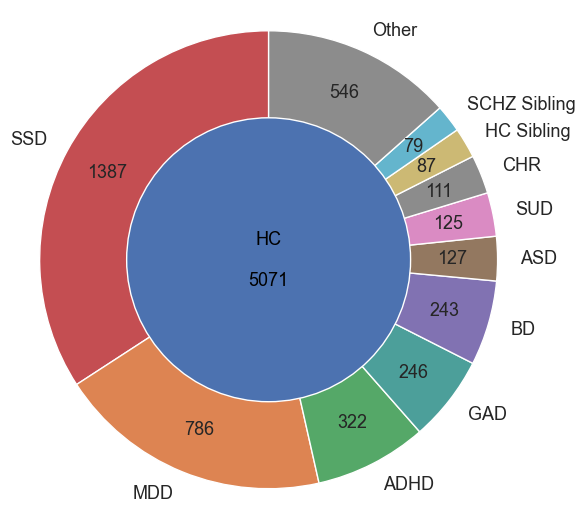

In [6]:
sns.set(style="white")

# -----------------------------
# ALL DIAGNOSES (EXCLUDING HC) DONUT
# -----------------------------
df_no_hc = df_exploded[
    (df_exploded["group_label"].notna()) &
    (df_exploded["group_label"] != "HC")
].copy()

df_no_hc["group_label"] = df_no_hc["group_label"].replace({"SCHZ": "SSD"})

diag_counts = df_no_hc["group_label"].value_counts().sort_values(ascending=False)

# Top N diagnoses + Other
top_n = 10
top_counts = diag_counts.iloc[:top_n]
other_count = diag_counts.iloc[top_n:].sum()

diag_counts_reduced = top_counts.copy()
if other_count > 0:
    diag_counts_reduced.loc["Other"] = other_count

plt.figure(figsize=(6.5, 6.5))

colors = [
    "#C44E52", "#DD8452", "#55A868", "#4C9F9A", "#8172B2",
    "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD", "#8C8C8C"
]

def autopct_counts(values):
    def inner(pct):
        total = sum(values)
        count = int(round(pct * total / 100.0))
        return f"{count}"
    return inner

plt.pie(
    diag_counts_reduced,
    labels=diag_counts_reduced.index,
    autopct=autopct_counts(diag_counts_reduced),
    startangle=90,
    colors=colors[:len(diag_counts_reduced)],
    pctdistance=0.8,
    wedgeprops={"edgecolor": "white"},
    textprops={"fontsize": 13}
)

# Inner blue circle with the HC count
centre_circle = plt.Circle((0, 0), 0.62, fc="#4C72B0")
plt.gca().add_artist(centre_circle)

plt.text(
    0, 0.09, "HC",
    ha="center", va="center",
    fontsize=13, color="black"
)
plt.text(
    0, -0.09, f"{len(hc_ids)}",
    ha="center", va="center",
    fontsize=13, color="black"
)

plt.axis("equal")
plt.savefig("figA1.pdf", format="pdf", bbox_inches="tight")
plt.show()

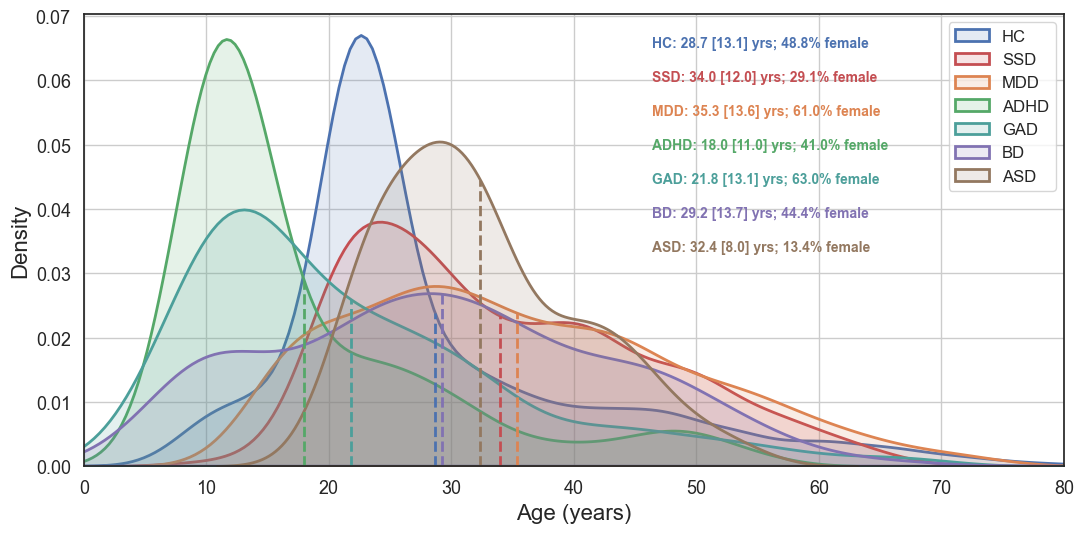

In [10]:
sns.set(style="white")

# -----------------------------
# AGE DISTRIBUTION: TOP 6 DIAGNOSES + HC
# -----------------------------
df_pat_long = df_exploded[
    (df_exploded["group_label"].notna()) &
    (df_exploded["group_label"] != "HC")
].copy()

df_pat_long["group_label"] = df_pat_long["group_label"].replace({"SCHZ": "SSD"})

df_pat_long = df_pat_long.drop_duplicates(
    subset=["participant_id", "group_label"], keep="first"
)

top_groups = df_pat_long["group_label"].value_counts().head(6).index
df_top = df_pat_long[df_pat_long["group_label"].isin(top_groups)].copy()

sex_map = {0: "Female", 1: "Male"}

fig, ax = plt.subplots(figsize=(11, 5.5))

colors = [
    "#C44E52",  # Muted red
    "#DD8452",  # Orange
    "#55A868",  # Green
    "#4C9F9A",  # Teal
    "#8172B2",  # Purple
    "#937860",  # Brown
]

hc_color = "#4C72B0"  # HC: blue

stats_lines = []
stats_colors = []

# HC curve first
ages_hc = pd.to_numeric(df_hc["age"], errors="coerce").dropna()

if len(ages_hc) > 1:
    sns.kdeplot(
        ages_hc, fill=True, linewidth=2,
        color=hc_color, label="HC", alpha=0.15, ax=ax
    )

    mean_age = ages_hc.mean()
    kde = gaussian_kde(ages_hc)
    y_mean = kde(mean_age)[0]

    ax.plot([mean_age, mean_age], [0, y_mean],
            color=hc_color, linestyle="--", linewidth=2)

    sex_clean = pd.to_numeric(df_hc["sex"], errors="coerce")
    sex = sex_clean.map(sex_map).dropna()
    sex_pct = sex.value_counts(normalize=True) * 100
    female_pct = sex_pct.get("Female", 0)

    stats_lines.append(
        f"HC: {mean_age:.1f} [{ages_hc.std():.1f}] yrs; {female_pct:.1f}% female"
    )
    stats_colors.append(hc_color)

# Top diagnosis curves
for group, color in zip(top_groups, colors):
    subset = df_top[df_top["group_label"] == group].copy()
    ages = pd.to_numeric(subset["age"], errors="coerce").dropna()

    if len(ages) < 2:
        continue

    sns.kdeplot(
        ages, fill=True, linewidth=2,
        color=color, label=group, alpha=0.15, ax=ax
    )

    mean_age = ages.mean()
    kde = gaussian_kde(ages)
    y_mean = kde(mean_age)[0]

    ax.plot([mean_age, mean_age], [0, y_mean],
            color=color, linestyle="--", linewidth=2)

    sex_clean = pd.to_numeric(subset["sex"], errors="coerce")
    sex = sex_clean.map(sex_map).dropna()
    sex_pct = sex.value_counts(normalize=True) * 100
    female_pct = sex_pct.get("Female", 0)

    stats_lines.append(
        f"{group}: {mean_age:.1f} [{ages.std():.1f}] yrs; {female_pct:.1f}% female"
    )
    stats_colors.append(color)

ax.set_xlabel("Age (years)", fontsize=16)
ax.set_ylabel("Density", fontsize=16)

ax.set_xticks(np.arange(0, 81, 10))
ax.set_xlim(0, 80)

ax.legend(fontsize=12, loc="upper right")
plt.xticks(fontsize=13)
plt.yticks(fontsize=13)
ax.grid(True)

# Colored stats box
x_pos = 0.58
y_start = 0.95
line_spacing = 0.075

for i, (line, color) in enumerate(zip(stats_lines, stats_colors)):
    ax.text(
        x_pos, y_start - i * line_spacing, line,
        transform=ax.transAxes,
        fontsize=10, color=color, fontweight="bold",
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0)
    )

plt.tight_layout()
plt.savefig("figA2.pdf", format="pdf", bbox_inches="tight")
plt.show()

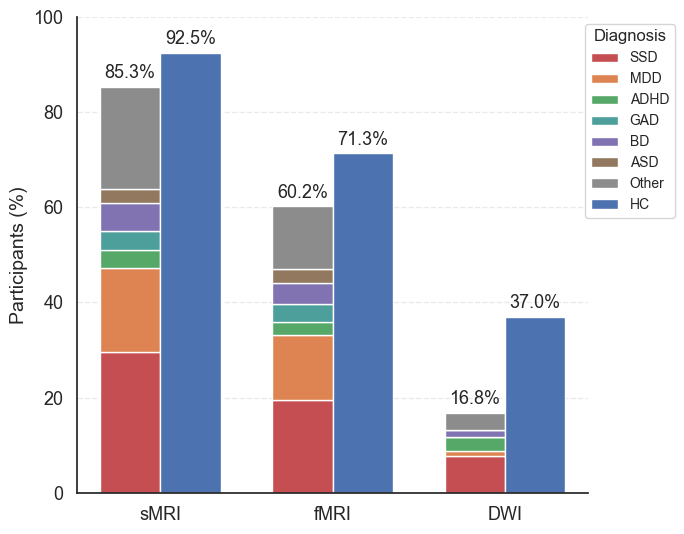

In [8]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# -----------------------------
# MODALITIES: TWO BARS PER MODALITY
# (patients = stacked diagnoses, HC = solid blue)
# -----------------------------
df_patients_mod = df_exploded[
    (df_exploded["group_label"].notna()) &
    (df_exploded["group_label"] != "HC")
].copy()

df_patients_mod["group_label"] = df_patients_mod["group_label"].replace({"SCHZ": "SSD"})

df_patients_mod = df_patients_mod.drop_duplicates(
    subset=["participant_id", "group_label"], keep="first"
)

top_groups = df_patients_mod["group_label"].value_counts().head(6).index

df_patients_mod["group_reduced"] = df_patients_mod["group_label"].where(
    df_patients_mod["group_label"].isin(top_groups), "Other"
)

colors_main = [
    "#C44E52",  # Muted red
    "#DD8452",  # Orange
    "#55A868",  # Green
    "#4C9F9A",  # Teal
    "#8172B2",  # Purple
    "#937860"   # Brown
]

color_other = "#8C8C8C"  # Other: grey
hc_color = "#4C72B0"     # HC: blue

ordered_groups = list(top_groups) + ["Other"]
colors_all = colors_main + [color_other]

# One row per patient-participant for the totals
patient_ids_set = set(df_patients_mod["participant_id"].unique())
df_patients_total = df[df["participant_id"].isin(patient_ids_set)].copy()

# -----------------------------
# STACKED VALUES (patients) + HC VALUES
# -----------------------------
stack_values = []

for modality in modalities:
    df_mod_have = df_patients_mod[df_patients_mod[modality] == 1]

    total_pct = pd.to_numeric(
        df_patients_total[modality], errors="coerce"
    ).mean() * 100

    if len(df_mod_have) == 0:
        stack_values.append([0] * len(ordered_groups))
        continue

    dist = (
        df_mod_have["group_reduced"]
        .value_counts(normalize=True)
        .reindex(ordered_groups, fill_value=0)
    )

    scaled = dist * total_pct
    stack_values.append(scaled.values)

stack_values = np.array(stack_values)

hc_values = [df_hc[m].mean() * 100 for m in modalities]

# -----------------------------
# PLOT
# -----------------------------
plt.figure(figsize=(7, 5.5))
plt.grid(axis="y", linestyle="--", alpha=0.4)

x = np.arange(len(modalities))
width = 0.35

bottom = np.zeros(len(modalities))

for i, (group, color) in enumerate(zip(ordered_groups, colors_all)):
    values = stack_values[:, i]

    plt.bar(
        x - width / 2,
        values,
        width=width,
        bottom=bottom,
        color=color,
        label=group
    )

    bottom += values

plt.bar(
    x + width / 2,
    hc_values,
    width=width,
    color=hc_color,
    label="HC"
)

# Total % labels
patient_totals = [
    pd.to_numeric(df_patients_total[col], errors="coerce").mean() * 100
    for col in modalities
]

for i, total in enumerate(patient_totals):
    plt.text(
        x[i] - width / 2, total + 1, f"{total:.1f}%",
        ha="center", va="bottom", fontsize=13
    )

for i, total in enumerate(hc_values):
    plt.text(
        x[i] + width / 2, total + 1, f"{total:.1f}%",
        ha="center", va="bottom", fontsize=13
    )

plt.xticks(x, labels, fontsize=13)
plt.ylabel("Participants (%)", fontsize=14)
plt.yticks(fontsize=13)
plt.ylim(0, 100)

sns.despine()

plt.legend(
    bbox_to_anchor=(0.98, 1),
    loc="upper left",
    fontsize=10,
    title="Diagnosis"
)

plt.tight_layout()
plt.savefig("figA3.pdf", format="pdf", bbox_inches="tight")
plt.show()